# 02 — Medidas de Tendência Central e de Dispersão

O notebook 01 terminou com o `describe`, que despeja uma porção de números: média, desvio padrão, mínimo, quartis, máximo. Agora vamos entender **cada um deles**: o que medem, como calculá-los à mão e quando eles **enganam**.

Resumir dados com poucos números responde duas perguntas:
1. **Onde ficam os valores típicos?** → medidas de **tendência central** (média, mediana, moda)
2. **Quão espalhados eles estão?** → medidas de **dispersão** (amplitude, variância, desvio padrão, quartis)

Neste notebook vamos:
- Calcular **média, mediana e moda** e ver como um **outlier** afeta cada uma
- Medir a dispersão com **variância, desvio padrão** e **intervalo interquartil (IQR)**
- Entender o misterioso **n − 1** da variância, com uma simulação
- Detectar **outliers** com a regra do IQR
- Medir a **assimetria** e a **curtose** de uma distribuição
- Descobrir por que a **média combina com o MSE** e a **mediana combina com o MAE**

## 1. Importando bibliotecas e carregando os dados

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats   # scipy.stats: funções estatísticas (assimetria, curtose, distribuições, testes...)

pd.set_option("display.precision", 3)
plt.rcParams["figure.dpi"] = 100

gorjetas = sns.load_dataset("tips")
gorjetas["percentual"] = gorjetas["tip"] / gorjetas["total_bill"] * 100   # a coluna criada no notebook 01
contas = gorjetas["total_bill"].to_numpy()

## 🎓 Conceito: média, mediana e moda

- **Média** (aritmética): soma tudo e divide pela quantidade. Para valores $x_1, x_2, \dots, x_n$:
$$\bar{x} = \frac{x_1 + x_2 + \dots + x_n}{n} = \frac{1}{n}\sum_{i=1}^{n} x_i$$
  O símbolo $\sum$ (sigma maiúsculo) significa "some todos". Lê-se $\bar{x}$ como "x barra".
- **Mediana:** o valor **do meio** depois de ordenar. Metade dos valores fica abaixo dela e metade acima. Com uma quantidade par de valores, é a média dos dois do meio.
- **Moda:** o valor **mais frequente**. É a única das três que funciona também para variáveis categóricas.

Analogia: a média é o **ponto de equilíbrio** de uma gangorra com os valores como pesos; a mediana é a pessoa **do meio da fila** quando todos se ordenam por altura.

In [2]:
# Média "à mão": sum() soma, len() conta os elementos.
media_mao = sum(contas) / len(contas)

# Mediana "à mão": ordenar e pegar o(s) do meio.
ordenadas = np.sort(contas)          # np.sort devolve uma cópia ordenada
n = len(ordenadas)
meio = n // 2                         # // é a divisão inteira: 244 // 2 = 122
# Com n par, a mediana é a média dos dois valores centrais (posições 121 e 122, contando a partir de 0).
mediana_mao = (ordenadas[meio - 1] + ordenadas[meio]) / 2

print(f"Média   à mão: {media_mao:.3f}   numpy: {np.mean(contas):.3f}")
print(f"Mediana à mão: {mediana_mao:.3f}   numpy: {np.median(contas):.3f}")

# Moda: faz sentido para valores que se repetem, como o número de pessoas por mesa.
# .mode() do pandas devolve uma Series (pode haver empate); [0] pega o primeiro.
print(f"\nModa de 'size': {gorjetas['size'].mode()[0]} pessoas")
print(f"Moda de 'day':  {gorjetas['day'].mode()[0]}")

Média   à mão: 19.786   numpy: 19.786
Mediana à mão: 17.795   numpy: 17.795

Moda de 'size': 2 pessoas
Moda de 'day':  Sat


**Conclusão:** os cálculos à mão batem com o numpy: a conta média é **US\$ 19,79** e a mediana, **US\$ 17,80**. A média é cerca de US\$ 2 maior que a mediana, porque algumas contas altas (até US\$ 50,81) "puxam" a média para cima, enquanto a mediana só olha para o valor do meio.

A moda faz mais sentido nas variáveis com valores repetidos: a mesa mais comum é a de **2 pessoas**, e o dia mais frequente é o **sábado**.

## 2. O efeito de um outlier

Um **outlier** (valor atípico) é um valor muito diferente dos demais. Ele pode ser um erro de digitação ou um caso real e raro. Vamos ver o que acontece se, por um erro, uma conta de US\$ 50,81 tivesse sido anotada como US\$ 5.081,00.

In [3]:
# .copy() cria uma cópia independente; sem ela, alterar "com_erro" também alteraria "contas".
com_erro = contas.copy()
posicao_maior = np.argmax(com_erro)      # argmax devolve a POSIÇÃO do maior valor
com_erro[posicao_maior] = 5081.00        # o "erro de digitação"

# Um dicionário de listas vira uma tabela: cada chave é uma coluna.
comparacao = pd.DataFrame({
    "dados corretos": [np.mean(contas), np.median(contas)],
    "com o erro": [np.mean(com_erro), np.median(com_erro)],
}, index=["média", "mediana"])
comparacao

,dados corretos,com o erro
média,19.786,40.401
mediana,17.795,17.795


**Conclusão:** um único valor errado **dobrou** a média: de US\$ 19,79 para **US\$ 40,40**, um número que não representa nenhuma mesa típica. A mediana **não se mexeu** (US\$ 17,80), porque o valor do meio continua sendo o mesmo; só mudou o maior valor.

Dizemos que a mediana é **robusta** a outliers, e a média não. Regra prática: quando os dados têm valores extremos (rendas, preços de casas, tempos de espera), a mediana costuma descrever melhor o "valor típico".

## 🎓 Conceito: medidas de dispersão

Duas turmas podem ter a mesma nota média 7: numa, todos tiraram 7; na outra, metade tirou 4 e metade tirou 10. A média não enxerga essa diferença. Precisamos medir o **espalhamento**:

- **Amplitude:** máximo − mínimo. Simples, mas depende só de dois valores (os mais extremos).
- **Variância:** a média dos **quadrados dos desvios** em relação à média:
$$s^2 = \frac{1}{n-1}\sum_{i=1}^{n} (x_i - \bar{x})^2$$
  Elevamos ao quadrado para que desvios para cima e para baixo não se cancelem. (O $n-1$ no lugar de $n$ será explicado mais adiante, com uma simulação.)
- **Desvio padrão:** a raiz quadrada da variância, $s = \sqrt{s^2}$. Ele volta para a **mesma unidade** dos dados (dólares, e não "dólares ao quadrado"), por isso é o mais usado. Interpretação aproximada: a distância **típica** de um valor até a média.
- **Coeficiente de variação (CV):** desvio padrão / média. Mede a dispersão **relativa**, permitindo comparar variáveis em escalas diferentes.

In [4]:
# Variância e desvio padrão "à mão", passo a passo.
media = contas.mean()
desvios = contas - media                 # vetorização: subtrai a média de cada conta
quadrados = desvios ** 2                 # ** é a potência em Python
variancia_mao = quadrados.sum() / (len(contas) - 1)
desvio_mao = np.sqrt(variancia_mao)

print(f"Soma dos desvios (sem elevar ao quadrado): {desvios.sum():.10f}   <- sempre zero!")
print(f"Variância à mão:      {variancia_mao:.3f} (dólares²)")
# ddof=1 significa "divida por n - 1". O padrão do numpy é ddof=0 (divide por n); o do pandas é ddof=1.
print(f"Variância numpy:      {np.var(contas, ddof=1):.3f}")
print(f"Desvio padrão à mão:  {desvio_mao:.3f}   numpy: {np.std(contas, ddof=1):.3f}   pandas: {gorjetas['total_bill'].std():.3f}")
print(f"Amplitude:            {contas.max() - contas.min():.2f}")

Soma dos desvios (sem elevar ao quadrado): -0.0000000000   <- sempre zero!
Variância à mão:      79.253 (dólares²)
Variância numpy:      79.253
Desvio padrão à mão:  8.902   numpy: 8.902   pandas: 8.902
Amplitude:            47.74


In [5]:
# Comparando a dispersão de variáveis em escalas diferentes com o coeficiente de variação.
resumo = pd.DataFrame({
    "média": gorjetas[["total_bill", "tip", "percentual"]].mean(),
    "desvio padrão": gorjetas[["total_bill", "tip", "percentual"]].std(),
})
resumo["CV"] = resumo["desvio padrão"] / resumo["média"]   # nova coluna calculada a partir das outras
resumo

,média,desvio padrão,CV
total_bill,19.786,8.902,0.450
tip,2.998,1.384,0.461
percentual,16.080,6.107,0.380


**Conclusão:** a soma dos desvios em relação à média é **zero** (a menos de erros minúsculos de arredondamento do computador), e é por isso que precisamos elevar ao quadrado. A variância da conta é **79,25 dólares²**, um número difícil de interpretar; o desvio padrão, **US\$ 8,90**, volta para dólares e é bem mais intuitivo.

O coeficiente de variação permite comparar variáveis em escalas diferentes: a conta (CV = 0,45) e a gorjeta em dólares (0,46) têm dispersão relativa parecida, e o **percentual** de gorjeta é a mais estável das três (0,38). Faz sentido: muita gente calcula a gorjeta como uma porcentagem fixa da conta.

## 3. Visualizando média e desvio padrão

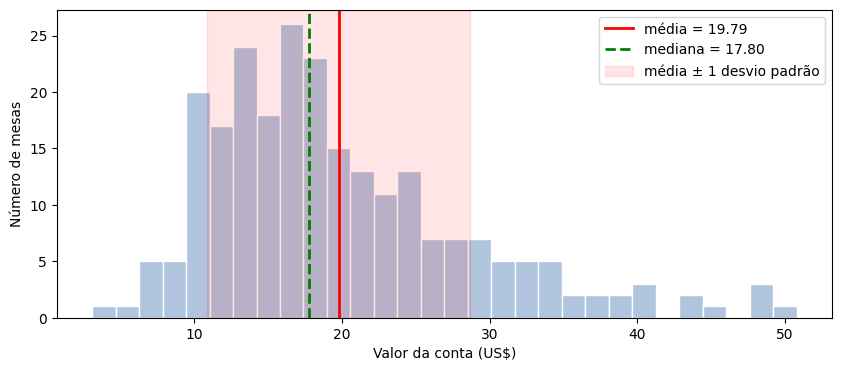

A menos de 1 desvio(s) padrão da média: 72.1% das mesas
A menos de 2 desvio(s) padrão da média: 94.3% das mesas
A menos de 3 desvio(s) padrão da média: 98.4% das mesas


In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(contas, bins=30, color="lightsteelblue", edgecolor="white")   # histograma (detalhes no notebook 03)
ax.axvline(media, color="red", linewidth=2, label=f"média = {media:.2f}")
ax.axvline(np.median(contas), color="green", linewidth=2, linestyle="--", label=f"mediana = {np.median(contas):.2f}")
# axvspan pinta uma faixa vertical: de (média - 1 desvio) até (média + 1 desvio).
ax.axvspan(media - desvio_mao, media + desvio_mao, color="red", alpha=0.1, label="média ± 1 desvio padrão")
ax.set_xlabel("Valor da conta (US$)")
ax.set_ylabel("Número de mesas")
ax.legend()
plt.show()

# Que fração das mesas fica a menos de 1 e de 2 desvios padrão da média?
# np.abs = valor absoluto; a comparação gera True/False e .mean() dá a proporção de True.
for k in [1, 2, 3]:
    dentro = np.mean(np.abs(contas - media) < k * desvio_mao)
    print(f"A menos de {k} desvio(s) padrão da média: {dentro:.1%} das mesas")   # :.1% formata como porcentagem

**Conclusão:** a faixa vermelha (média ± 1 desvio padrão, de cerca de US\$ 11 a US\$ 29) contém **72,1%** das mesas; a 2 desvios padrão estão **94,3%**, e a 3, **98,4%**. Esses números ficam perto da "regra 68–95–99,7" que vale para a distribuição normal (notebook 08). Não batem exatamente porque as contas não são normais: o histograma tem uma cauda longa para a direita, com contas de até US\$ 50, e a média (linha vermelha) fica à direita da mediana (linha verde tracejada).

## 🎓 Conceito: por que dividir por n − 1?

Queremos usar a **amostra** para estimar a variância da **população**. O problema: os desvios são medidos em relação à média **da amostra** ($\bar{x}$), e não à média verdadeira da população ($\mu$, a letra grega "mi"). Como $\bar{x}$ é calculada com os próprios dados, ela fica, por construção, "no meio deles", e os desvios ficam **um pouco menores** do que seriam em relação a $\mu$. Dividir por $n$ **subestima** a variância.

Dividir por $n - 1$ compensa exatamente esse efeito. Essa correção se chama **correção de Bessel**, e $n-1$ são os **graus de liberdade**: depois de fixar a média, só $n-1$ desvios podem variar livremente (o último é obrigado a fazer a soma dar zero, como vimos acima).

Em vez de acreditar na fórmula, vamos **simular**: tirar muitas amostras pequenas de uma população com variância conhecida e ver qual divisão acerta **em média**.

In [7]:
rng = np.random.default_rng(42)

# População: rng.normal sorteia de uma distribuição normal (notebook 08) com desvio padrão 10, logo variância 100.
variancia_verdadeira = 100
n_amostra = 5               # amostras bem pequenas, onde a diferença entre n e n-1 é grande
n_repeticoes = 100_000

# Sorteamos todas as amostras de uma vez: uma matriz com 100.000 linhas (amostras) e 5 colunas (valores).
amostras = rng.normal(loc=50, scale=10, size=(n_repeticoes, n_amostra))

# axis=1: calcula a variância de cada LINHA (cada amostra), devolvendo 100.000 variâncias.
var_n = amostras.var(axis=1, ddof=0)        # divide por n
var_n_1 = amostras.var(axis=1, ddof=1)      # divide por n - 1

print(f"Variância verdadeira da população:          {variancia_verdadeira}")
print(f"Média das variâncias dividindo por n:       {var_n.mean():.2f}")
print(f"Média das variâncias dividindo por n - 1:   {var_n_1.mean():.2f}")
print(f"Razão teórica (n-1)/n:                      {(n_amostra - 1) / n_amostra:.2f}")

Variância verdadeira da população:          100
Média das variâncias dividindo por n:       80.07
Média das variâncias dividindo por n - 1:   100.09
Razão teórica (n-1)/n:                      0.80


**Conclusão:** a simulação confirma a teoria. Com amostras de 5 valores de uma população de variância 100, dividir por $n$ dá em média **80,07**, um erro de 20% para baixo, exatamente a razão $(n-1)/n = 0{,}80$. Dividir por $n-1$ dá em média **100,09**, praticamente o valor verdadeiro.

Dizemos que a variância com $n-1$ é um **estimador não viesado**: ela não erra sistematicamente para nenhum lado. Com amostras grandes a diferença some (com $n = 244$, a razão é 0,996), mas com amostras pequenas ela importa. Vamos voltar ao conceito de **viés de um estimador** no notebook 11.

## 🎓 Conceito: quantis, quartis e intervalo interquartil

O **quantil** de 0,25 é o valor que deixa **25%** dos dados abaixo dele. Os mais usados:
- **Quartis:** Q1 (25%), Q2 (50%, a própria mediana) e Q3 (75%). São as linhas `25%`, `50%` e `75%` do `describe`.
- **Percentis:** o percentil 90 deixa 90% abaixo. (Se você já recebeu um resultado do tipo "seu filho está no percentil 80 de altura", é isso.)
- **Intervalo interquartil (IQR):** Q3 − Q1. É a largura da faixa onde estão os **50% do meio** dos dados.

O IQR é uma medida de dispersão **robusta**: como ignora os 25% de cada ponta, outliers não o afetam, diferente do desvio padrão.

In [8]:
# np.quantile aceita uma lista de proporções e devolve os quantis correspondentes.
q1, q2, q3 = np.quantile(contas, [0.25, 0.50, 0.75])   # "desempacotamento": 3 valores em 3 variáveis
iqr = q3 - q1
print(f"Q1 = {q1:.2f}   Q2 (mediana) = {q2:.2f}   Q3 = {q3:.2f}   IQR = {iqr:.2f}")
print(f"Percentil 90: {np.quantile(contas, 0.90):.2f}")

# Robustez: comparando o efeito do erro de digitação no desvio padrão e no IQR.
iqr_erro = np.subtract(*np.quantile(com_erro, [0.75, 0.25]))   # o * "abre" a lista em dois argumentos: Q3 - Q1
print(f"\nDesvio padrão: {np.std(contas, ddof=1):8.2f} → com o erro: {np.std(com_erro, ddof=1):8.2f}")
print(f"IQR:           {iqr:8.2f} → com o erro: {iqr_erro:8.2f}")

Q1 = 13.35   Q2 (mediana) = 17.80   Q3 = 24.13   IQR = 10.78
Percentil 90: 32.24

Desvio padrão:     8.90 → com o erro:   324.14
IQR:              10.78 → com o erro:    10.78


**Conclusão:** metade das contas fica entre **US\$ 13,35** (Q1) e **US\$ 24,13** (Q3), uma faixa de largura **US\$ 10,78** (o IQR). E 90% das contas ficam abaixo de **US\$ 32,24**.

O teste de robustez é claro: o erro de digitação fez o desvio padrão saltar de US\$ 8,90 para **US\$ 324,14**, enquanto o IQR ficou **exatamente igual** (US\$ 10,78). Assim como a mediana, o IQR não se deixa levar por um valor extremo.

## 4. Detectando outliers com a regra do IQR

Uma regra prática muito usada (a mesma que o **boxplot** usa, como veremos no notebook 03): um valor é considerado **outlier** se estiver mais de **1,5 × IQR** abaixo de Q1 ou acima de Q3.

$$\text{outlier se } x < Q_1 - 1{,}5 \cdot \text{IQR} \quad \text{ou} \quad x > Q_3 + 1{,}5 \cdot \text{IQR}$$

Vamos aplicá-la ao **percentual de gorjeta**.

In [9]:
def limites_iqr(valores, fator=1.5):
    """Devolve os limites inferior e superior da regra do IQR."""
    q1, q3 = np.quantile(valores, [0.25, 0.75])
    iqr = q3 - q1
    return q1 - fator * iqr, q3 + fator * iqr   # uma função pode devolver vários valores (uma tupla)


inferior, superior = limites_iqr(gorjetas["percentual"])
print(f"Limites: abaixo de {inferior:.1f}% ou acima de {superior:.1f}% é outlier")

# O operador | significa "ou" entre máscaras (o "e" seria &). Os parênteses são obrigatórios.
outliers = gorjetas[(gorjetas["percentual"] < inferior) | (gorjetas["percentual"] > superior)]
outliers.sort_values("percentual")

Limites: abaixo de 3.6% ou acima de 28.5% é outlier


,total_bill,tip,sex,smoker,day,time,size,percentual
232,11.61,3.39,Male,No,Sat,Dinner,2,29.199
67,3.07,1.00,Female,Yes,Sat,Dinner,1,32.573
178,9.60,4.00,Female,Yes,Sun,Dinner,2,41.667
172,7.25,5.15,Male,Yes,Sun,Dinner,2,71.034


In [10]:
# Média e mediana do percentual, com e sem esses outliers.
sem_outliers = gorjetas.drop(index=outliers.index)   # .drop(index=...) remove as linhas pelos rótulos
print(f"Com outliers: média {gorjetas['percentual'].mean():.2f}%  mediana {gorjetas['percentual'].median():.2f}%  desvio {gorjetas['percentual'].std():.2f}")
print(f"Sem outliers: média {sem_outliers['percentual'].mean():.2f}%  mediana {sem_outliers['percentual'].median():.2f}%  desvio {sem_outliers['percentual'].std():.2f}")

Com outliers: média 16.08%  mediana 15.48%  desvio 6.11
Sem outliers: média 15.62%  mediana 15.38%  desvio 4.53


**Conclusão:** a regra do IQR aponta **4 outliers**, todos acima de 28,5% de gorjeta (nenhum abaixo do limite inferior de 3,6%). O mais extremo é a mesa de **71%** de gorjeta que encontramos no notebook 01. Repare que três deles são contas pequenas (de US\$ 3,07 a US\$ 9,60): uma gorjeta de US\$ 4 numa conta de US\$ 9,60 vira 42%.

Removê-los quase não muda a **mediana** (15,48% → 15,38%), mas muda a **média** (16,08% → 15,62%) e, principalmente, o **desvio padrão** (6,11 → 4,53): quatro mesas em 244 eram responsáveis por boa parte da dispersão.

Atenção: "ser outlier pela regra do IQR" **não** quer dizer "é um erro e deve ser apagado". Essas gorjetas generosas provavelmente são reais. A regra serve para **chamar a atenção** para valores que merecem uma olhada.

## 🎓 Conceito: assimetria e curtose

Duas medidas descrevem a **forma** de uma distribuição:

- **Assimetria** (*skewness*): mede se uma das "caudas" é mais comprida.
  - ≈ 0: simétrica (os dois lados parecidos).
  - **> 0: assimetria à direita** (cauda longa para os valores altos). Típico de valores monetários, rendas e tempos de espera. Nesse caso, **média > mediana**, porque os valores grandes puxam a média.
  - < 0: assimetria à esquerda (cauda longa para os valores baixos), por exemplo notas numa prova fácil.
- **Curtose** (*kurtosis*): mede o "peso das caudas", ou seja, a tendência a produzir valores extremos. O `scipy` usa a **curtose em excesso**, que vale 0 para a distribuição normal. Valores **positivos** indicam caudas mais pesadas que a normal (mais outliers).

In [11]:
# Dados simulados com formas conhecidas, para comparar com as colunas do tips.
rng = np.random.default_rng(42)
exemplos = {
    "simétrica (normal)": rng.normal(size=10_000),
    "assimétrica à direita (exponencial)": rng.exponential(size=10_000),
    "assimétrica à esquerda (100 - exponencial)": 100 - rng.exponential(size=10_000),
    "caudas pesadas (t de Student)": rng.standard_t(df=3, size=10_000),
}

# Laço sobre um dicionário: .items() devolve pares (chave, valor).
linhas = []
for nome, valores in exemplos.items():
    linhas.append({"distribuição": nome,
                   "assimetria": stats.skew(valores),
                   "curtose (excesso)": stats.kurtosis(valores),
                   "média - mediana": np.mean(valores) - np.median(valores)})
for coluna in ["total_bill", "tip", "percentual"]:
    valores = gorjetas[coluna]
    linhas.append({"distribuição": f"tips: {coluna}",
                   "assimetria": stats.skew(valores),
                   "curtose (excesso)": stats.kurtosis(valores),
                   "média - mediana": valores.mean() - valores.median()})

# Uma lista de dicionários também vira um DataFrame: cada dicionário é uma linha.
pd.DataFrame(linhas).set_index("distribuição")

,assimetria,curtose (excesso),média - mediana
distribuição,,,
simétrica (normal),-0.003,0.053,0.003
assimétrica à direita (exponencial),2.043,6.292,0.308
assimétrica à esquerda (100 - exponencial),-2.099,7.013,-0.322
caudas pesadas (t de Student),0.930,34.307,0.023
tips: total_bill,1.126,1.169,1.991
tips: tip,1.456,3.550,0.098
tips: percentual,3.329,26.554,0.603


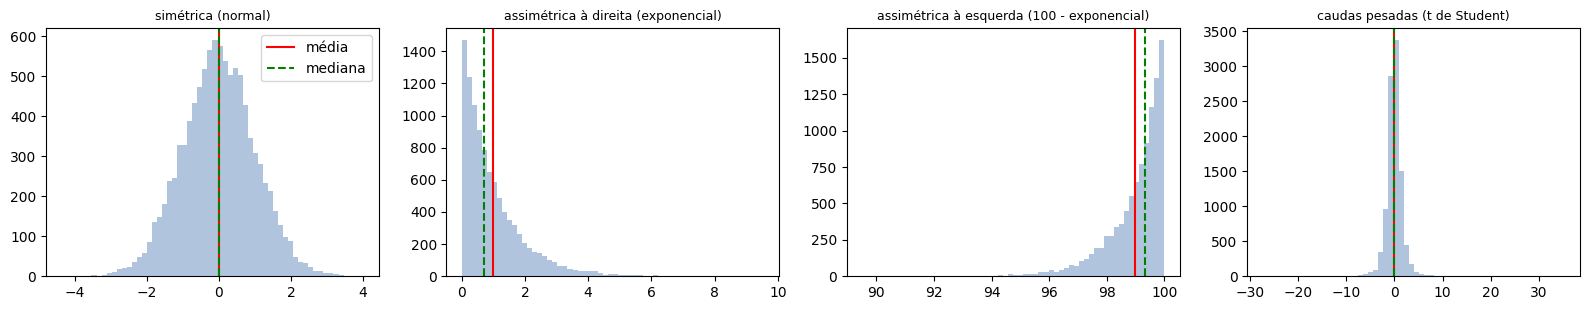

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for ax, (nome, valores) in zip(axes, exemplos.items()):
    ax.hist(valores, bins=60, color="lightsteelblue")
    ax.axvline(np.mean(valores), color="red", label="média")
    ax.axvline(np.median(valores), color="green", linestyle="--", label="mediana")
    ax.set_title(nome, fontsize=9)
axes[0].legend()
plt.tight_layout()
plt.show()

**Conclusão:** - A **normal** simulada tem assimetria e curtose praticamente zero, e a média coincide com a mediana.
- A **exponencial** tem assimetria **+2,04**, e a média fica à direita da mediana (+0,31); a versão espelhada tem assimetria **−2,10**, e a média fica à esquerda (−0,32). Nos gráficos, a linha vermelha (média) sempre fica do lado da cauda longa.
- A **t de Student** é quase simétrica no gráfico, mas tem curtose **34,3**: ela produz alguns valores extremos (repare no eixo x indo de −30 a +30 enquanto quase tudo está entre −5 e 5). Os poucos extremos também deixam a assimetria calculada instável (0,93), mesmo com uma distribuição simétrica: assimetria e curtose são muito sensíveis a outliers.
- No **tips**, as três colunas são assimétricas à direita: conta (1,13), gorjeta (1,46) e, sobretudo, o **percentual (3,33, com curtose 26,6)**, puxado pela mesa de 71%.

## 5. Resumos por grupo

Medidas de resumo ficam ainda mais úteis quando **comparamos grupos**. O `groupby` do pandas separa as linhas por categoria e calcula o resumo de cada grupo.

In [13]:
# groupby("day") separa por dia; ["percentual"] escolhe a coluna; .agg aplica várias funções de uma vez.
# observed=True mostra só as categorias que existem nos dados.
por_dia = gorjetas.groupby("day", observed=True)["percentual"].agg(["count", "mean", "median", "std"])
por_dia

,count,mean,median,std
day,,,,
Thur,62,16.128,15.385,3.865
Fri,19,16.991,15.562,4.767
Sat,87,15.315,15.183,5.129
Sun,76,16.690,16.110,8.474


**Conclusão:** os percentuais **típicos** (a mediana) são parecidos em todos os dias, de **15,2%** no sábado a **16,1%** no domingo. O domingo tem o maior desvio padrão (**8,47**), mas lembre-se de que a mesa de 71% caiu num domingo: um único outlier é capaz de inflar a dispersão de um grupo inteiro. E a sexta tem só **19 mesas**, então a média dela (17,0%) é bem menos confiável que a dos outros dias.

Diferenças pequenas entre grupos podem ser só **acaso da amostra**, como as cinco médias diferentes do notebook 01. Saber quando uma diferença é "real" é o assunto dos **testes de hipótese** (notebook 12).

## 🎓 Conceito: a média minimiza o erro quadrático, a mediana minimiza o erro absoluto

Imagine que você precisa **prever o valor da próxima conta** com um único número $c$, sem nenhuma outra informação. Qual número escolher? Depende de como você mede o erro:

- Se o erro for o **quadrado** da diferença, $(x_i - c)^2$ (como no **MSE**), o melhor $c$ é a **média**.
- Se o erro for o **valor absoluto** da diferença, $|x_i - c|$ (como no **MAE**), o melhor $c$ é a **mediana**.

Vamos verificar isso testando muitos valores de $c$.

🔗 **Ponte para o ML:** é exatamente o **baseline** do ML-01, o modelo que "sempre prevê a média". Ele é o melhor modelo constante para o RMSE. E é por isso que o R² compara o modelo com a média: R² = 0 significa "não melhor que a média".

c que minimiza o MSE: 19.79   (média   = 19.79)
c que minimiza o MAE: 17.78   (mediana = 17.80)


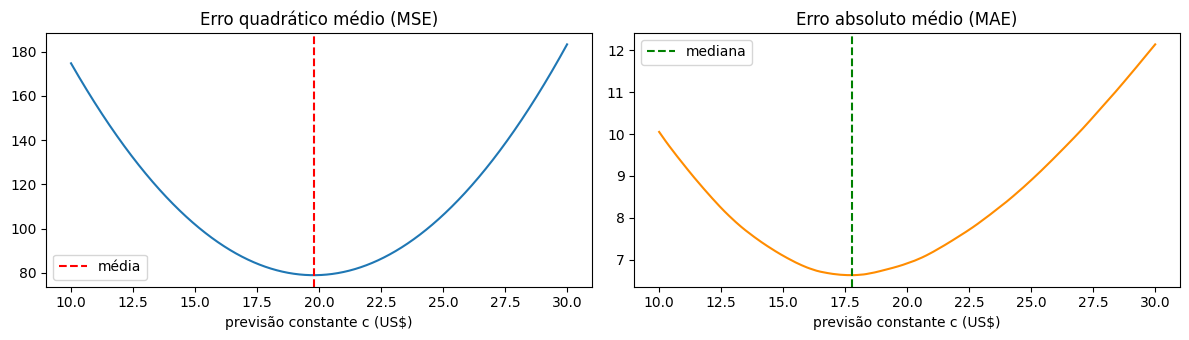

In [14]:
candidatos = np.linspace(10, 30, 2001)   # 2001 valores igualmente espaçados entre 10 e 30

# List comprehension: [expressão for item in lista] cria uma lista calculando a expressão para cada item.
mse = [np.mean((contas - c) ** 2) for c in candidatos]
mae = [np.mean(np.abs(contas - c)) for c in candidatos]

melhor_mse = candidatos[np.argmin(mse)]   # argmin = posição do menor valor
melhor_mae = candidatos[np.argmin(mae)]
print(f"c que minimiza o MSE: {melhor_mse:.2f}   (média   = {np.mean(contas):.2f})")
print(f"c que minimiza o MAE: {melhor_mae:.2f}   (mediana = {np.median(contas):.2f})")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(candidatos, mse)
axes[0].axvline(np.mean(contas), color="red", linestyle="--", label="média")
axes[0].set_title("Erro quadrático médio (MSE)")
axes[1].plot(candidatos, mae, color="darkorange")
axes[1].axvline(np.median(contas), color="green", linestyle="--", label="mediana")
axes[1].set_title("Erro absoluto médio (MAE)")
for ax in axes:
    ax.set_xlabel("previsão constante c (US$)")
    ax.legend()
plt.tight_layout()
plt.show()

**Conclusão:** a previsão constante que minimiza o MSE é **19,79**, exatamente a média, e a que minimiza o MAE é **17,78**, colada na mediana (17,80). A pequena diferença no MAE não é um erro: com uma quantidade par de valores, o MAE fica **plano** entre os dois valores centrais (17,78 e 17,81), e qualquer número entre eles é igualmente bom.

Os gráficos mostram outra diferença: a curva do MSE é uma parábola suave, e a do MAE é formada por pequenos segmentos de reta. Isso explica um fato do ML-01: um modelo treinado para minimizar o erro quadrático persegue a **média**, e por isso é mais sensível a outliers do que um que minimiza o erro absoluto.

## 6. Resumo e próximos passos

| Medida | O que mede | Robusta a outliers? |
|---|---|---|
| Média | centro (ponto de equilíbrio) | ❌ |
| Mediana | centro (valor do meio) | ✅ |
| Moda | valor mais frequente | ✅ (serve para categóricas) |
| Amplitude | dispersão total | ❌ |
| Variância / desvio padrão | dispersão em torno da média | ❌ |
| IQR | dispersão dos 50% do meio | ✅ |
| Assimetria | qual cauda é mais longa | ❌ |
| Curtose | peso das caudas | ❌ |

**Conceitos que você aprendeu**
- Média, mediana e moda, e como um **outlier** distorce a média, mas não a mediana.
- **Variância e desvio padrão**, e a **correção de Bessel** ($n-1$) comprovada por simulação.
- **Quantis, quartis e IQR**, e a **regra de 1,5 × IQR** para detectar outliers.
- **Assimetria** (média > mediana na assimetria à direita) e **curtose**.
- A média minimiza o **MSE** e a mediana minimiza o **MAE**.

**Python novo:** `np.mean`, `np.median`, `np.sort`, `//`, `.mode()`, `np.argmax` / `np.argmin`, `.copy()`, `ddof`, `axis=1`, `np.quantile`, `np.linspace`, funções com `def` e `return`, list comprehension, `|` entre máscaras, `.drop(index=...)`, `.sort_values`, `scipy.stats.skew` / `kurtosis`, `.groupby().agg()`.

**Próximo notebook:** os números resumem, mas **escondem** muita coisa. No notebook 03 vamos **olhar** as distribuições com histogramas, densidades, boxplots e a função de distribuição acumulada, e ver como a **transformação logarítmica** "desentorta" uma distribuição assimétrica.